parent: Preselection_v6

In [3]:
import os, sys
import numpy as np
import pickle
import uproot
import glob
import pandas as pd
from tqdm import tqdm
import json
import ROOT as rt
import fnmatch

## user define
sys.path.append('.')
sys.path.append('./Utils')
from Plotter import HistStack

from beeps import *

Welcome to JupyROOT 6.28/00


# Set config

In [1]:
# ERA="ee17"
# ERA="ee16pre"
# # ERA="mm18"
# ERA="em18"
# # DATE = '20230129_17_eleffmva'
# DATE = '20230301_18'
# # DATE = '20230130_18_dyhighworctight'
# # INPUTDIR = "/eos/user/h/hkwon/Run2/20230130_18_dyhighworctight/mm/"
# INPUTDIR = "/eos/user/h/hkwon/Run2/20230301_18/em/"
import sys
ERA = sys.argv[1]
DATE = sys.argv[2]
INPUTDIR = sys.argv[3]

DUMP_PKL = False
DRAW_SR = True
RUN_SIDEBAND_MET = False
RUN_SIDEBAND_MASS = False
RUN_SIDEBAND_PT = False
DUMP_SIDEBAND_MET_PKL = False
DUMP_SIDEBAND_MASS_PKL = False
DUMP_SIDEBAND_PT_PKL = False
RUN_BTAG = True
EXPORT_VARIABLE = False

# # # for dev
# ERA = "ee18"
# DATE = "20230622jer_18"
# INPUTDIR = "/eos/user/h/hkwon/SWAN_projects/Zpeak/20230622jer_18/Presel"


# Load data

In [4]:
with open(INPUTDIR+'/'+ERA+'/nested_dic_df_SR1.pkl', 'rb') as f:
    nested_dic_df = pickle.load(f)
with open(INPUTDIR+'/'+ERA+'/nested_dic_df_TTCR.pkl', 'rb') as f:
    nested_dic_df1 = pickle.load(f)

dic_df_all = [nested_dic_df['raw'], nested_dic_df1['raw']]
dic_df_met_u_all = [nested_dic_df['met_u'], nested_dic_df1['met_u']]
dic_df_met_d_all = [nested_dic_df['met_d'], nested_dic_df1['met_d']]    
dic_df_met_ue_u_all = [nested_dic_df['met_ue_u'], nested_dic_df1['met_ue_u']]
dic_df_met_ue_d_all = [nested_dic_df['met_ue_d'], nested_dic_df1['met_ue_d']]

dic_df, dic_df_met_u, dic_df_met_d, dic_df_met_ue_u, dic_df_met_ue_d = [{} for _ in range(5)]

for key in dic_df_all[0]:
    list_raw, list_met_u, list_met_d, list_met_ue_u, list_met_ue_d = [[] for _ in range(5)]
    for i in range(2):
        try:
            list_raw.append(dic_df_all[i][key])
            list_met_u.append(dic_df_met_u_all[i][key])
            list_met_d.append(dic_df_met_d_all[i][key])            
            list_met_ue_u.append(dic_df_met_ue_u_all[i][key])
            list_met_ue_d.append(dic_df_met_ue_d_all[i][key])
        except:
            print("missing:", key)
    dic_df[key]=pd.concat(list_raw, ignore_index=True)
    dic_df_met_u[key]=pd.concat(list_met_u, ignore_index=True)
    dic_df_met_d[key]=pd.concat(list_met_d, ignore_index=True)
    dic_df_met_ue_u[key]=pd.concat(list_met_ue_u, ignore_index=True)
    dic_df_met_ue_d[key]=pd.concat(list_met_ue_d, ignore_index=True)

dic_df_all.clear()    
dic_df_met_u_all.clear()    
dic_df_met_d_all.clear()    
dic_df_met_ue_u_all.clear()    
dic_df_met_ue_d_all.clear()    
    


In [11]:
dic_df_raw=dic_df
dic_nested_shape_sys={}
dic_nested_shape_sys["met_u"]=dic_df_met_u
dic_nested_shape_sys["met_d"]=dic_df_met_d    
dic_nested_shape_sys["met_ue_u"]=dic_df_met_ue_u
dic_nested_shape_sys["met_ue_d"]=dic_df_met_ue_d 

In [7]:
# get x-sec
dic_xsec={}
with open('config/CrossSection.json') as json_file:
    data = json.load(json_file)
    dic_xsec=data
print(dic_xsec)

{'Data': 1, 'DY': 6077.22, 'DY500To700': 0.2558, 'DY700To800': 0.04023, 'DY800To1000': 0.03406, 'DY1000To1500': 0.01828, 'DY1500To2000': 0.002367, 'DY2000To3000': 0.0005409, 'TT': 88.29, 'TTUp': 88.29, 'TTDown': 88.29, 'TThdampUp': 88.29, 'TThdampDown': 88.29, 'TTSemi': 365.34, 'TTZ': 0.2432, 'top': 34.91, 'antitop': 34.91, 'WW': 12.82, 'WZ': 5.23, 'WZQQ': 6.42, 'ZZ': 0.6008, 'WWW': 0.0072, 'WWZ': 0.1707, 'HWW': 0.31, 'H': 2.78, 'Zp-1700_CH-345': 0.03523, 'Zp-1700_CH-595': 0.03523, 'Zp-1700_CH-845': 0.03523, 'Zp-2100_CH-345': 0.01198, 'Zp-2100_CH-595': 0.01198, 'Zp-2100_CH-845': 0.01198, 'Zp-2500_CH-345': 0.004396, 'Zp-2500_CH-595': 0.004396, 'Zp-2500_CH-845': 0.004396, 'Zp-2500_CH-1095': 0.004396, 'Zp-2900_CH-345': 0.001768, 'Zp-2900_CH-595': 0.001768, 'Zp-2900_CH-845': 0.001768, 'Zp-2900_CH-1095': 0.001768, 'Zp-2900_CH-1345': 0.001768, 'Zp-3300_CH-345': 0.000729, 'Zp-3300_CH-595': 0.000729, 'Zp-3300_CH-845': 0.000729, 'Zp-3300_CH-1095': 0.000729, 'Zp-3300_CH-1345': 0.000729, 'Zp-3300

# Draw

In [6]:
# draw
# get plot configuration
dic_variable={
    "PuppiMET_pre": [14, 100, 660, "Puppi p_{T}^{miss} [GeV]"],    
# #     "MET_pre": [28, 0, 660, "p_{T}^{miss} [GeV]"],    
    "mass_pre": [22, 100, 1000, "M_{ll} [GeV]"],
    "pt_lead_pre": [15, 80,  660, "p_{T}(l_{lead}) [GeV]"],
    "pt_trail_pre": [15, 40, 520, "p_{T}(l_{trail}) [GeV]"],
    "Zpt_pre": [25, 0, 500, "p_{T}(ll) [GeV]"],
    "MT_pre": [27, 0, 550, "M_{T} [GeV]"],
    "MT2_pre": [17, 0, 350, "M_{T2} [GeV]"],
    "U_pre": [14, 0, 660, "U [GeV]"],
#     "HT_pre": [14, 0, 660, "HT [GeV]"],
    "JZB_pre": [14, 80, 660, "JZB"],
    "dPhill_pre": [17, 0, 3.4, "#Delta#phi(l,l)"],
    "dPhilMET_pre": [17, 0, 3.4, "#Delta#phi(l,p_{T}^{miss})"],
    "dRll_pre": [30, 0, 6, "#DeltaR(l,l)"],
    "dPhillMET_pre": [17, 0, 3.4, "#Delta#phi(ll,p_{T}^{miss})"],
# # #     "MC1C1_pre": [36, 180, 900, "MC1C1 [GeV]"], 
# # #     "H3PP_pre": [41, 80, 900, "H3PP [GeV]"], 
# # #     "H3TPP_pre": [40, 0, 800, "H3TPP [GeV]"], 
    "eta_lead_pre": [15, -3, 3, "#eta(l_{lead})"],
    "eta_trail_pre": [15, -3, 3, "#eta(l_{trail})"],
# # #     "phi_lead_pre": [40, -4, 4, "#phi(l_{lead})"],
# # #     "phi_trail_pre": [40, -4, 4, "#phi(l_{trail})"], 
    "PuppiMET_phi_pre": [20, -4, 4, "Puppi p_{T}^{miss} #phi(l_{trail})"],     
    "nbjetflav_pre": [7, 0, 7, "N bjetflav"],     
#     "nbjet_pre": [10, 0, 10, "N bjet"],     
    "njet_pre": [10, 0, 10, "N jet"],     
#     "njet_l_pre": [10, 0, 10, "N  l jet"],     
#     "njet_c_pre": [10, 0, 10, "N  c jet"],     
#     "njet_b_pre": [10, 0, 10, "N  b jet"],     
#     "btagSF_pre": [100, 0, 10, "SV dxy"],     
}
# if "em" in ERA:
#     dic_variable["pt_el_pre"] = [15, 20,  660, "p_{T}(e) [GeV]"]
#     dic_variable["pt_mu_pre"] = [15, 20,  660, "p_{T}(#mu) [GeV]"]
print(dic_variable)
list_variables = [(key, dic_variable[key]) for key in dic_variable]
print(list_variables)

{'pt_lead_pre': [15, 80, 660, 'p_{T}(l_{lead}) [GeV]'], 'pt_trail_pre': [15, 40, 520, 'p_{T}(l_{trail}) [GeV]'], 'nbjetflav_pre': [7, 0, 7, 'N bjetflav'], 'njet_pre': [10, 0, 10, 'N jet']}
[('pt_lead_pre', [15, 80, 660, 'p_{T}(l_{lead}) [GeV]']), ('pt_trail_pre', [15, 40, 520, 'p_{T}(l_{trail}) [GeV]']), ('nbjetflav_pre', [7, 0, 7, 'N bjetflav']), ('njet_pre', [10, 0, 10, 'N jet'])]


In [7]:
# SYS_LIST = ["puweight", "l1prefiring", "effSF", "topSF", "met", "metue", "trigSF", "hdamp", "PS"]
SYS_LIST = ["puweight", "l1prefiring", "effSF", "topSF", "met", "metue", "trigSF", "hdamp", "PS", "btagSF"]
# SYS_LIST = ["met", "metue"]
# SYS_LIST = ["hdamp", "PS"]

In [8]:
import math
# sys_list = ["puweight", "l1prefiring", "effSF", "topSF", "trigSF", "met", "scale"]
# sys_list = ["puweight", "l1prefiring", "effSF", "topSF", "trigSF", "met"]
# sys_list = ["puweight", "l1prefiring", "effSF", "topSF", "met"]
sys_list = SYS_LIST
# sys_list = ["l1prefiring"]

def draw_with_systematics(dic_df_raw, dic_nested_shape_sys, sys_list, variable, r, region, threshold):
    """
        draw histograms with sys variations, return sys uncertainty dic
    """
    dic_sys = {}
    dic_sys_sqr = {}
    # nominal weight plot
    hist=HistStack(dic_df_raw, variable, 'weight', r[0], r[1], r[2], r[3])            
    c1=hist.draw_hist("Zp-2500_CH-345", ERA, file_name=DATE+"/Presel/"+ERA+"/"+region+"/sys/norm_"+query_str)     
    dic_yields = hist.get_yields_by_bin()
    bkg_norm = dic_yields['bkg']

    for s in sys_list:
        if "met" in s or "scale" in s: # fill later
            continue
        # up
        hist=HistStack(dic_df_raw, variable, 'weight'+s+'Up', r[0], r[1], r[2], r[3])            
        c1=hist.draw_hist("Zp-2500_CH-345", ERA, file_name=DATE+"/Presel/"+ERA+"/"+region+"/sys/systUp_"+s+query_str, blind_from=threshold)     
        dic_yields = hist.get_yields_by_bin()
        sysUp = dic_yields['bkg']
        dic_sys[s+'Up'] = np.array(sysUp) - np.array(bkg_norm)
        # down
        hist=HistStack(dic_df_raw, variable, 'weight'+s+'Down', r[0], r[1], r[2], r[3])            
        c1=hist.draw_hist("Zp-2500_CH-345", ERA, file_name=DATE+"/Presel/"+ERA+"/"+region+"/sys/systDown_"+s+query_str)     
        dic_yields = hist.get_yields_by_bin()
        sysDown = dic_yields['bkg']
        dic_sys[s+'Down'] = np.array(sysDown) - np.array(bkg_norm)
    if "el_pre" not in variable and "mu_pre" not in variable: #temp
        # shape sys
        hist=HistStack(dic_nested_shape_sys['met_u'], variable, 'weightmetUp', r[0], r[1], r[2], r[3])            
        c1=hist.draw_hist("Zp-2500_CH-345", ERA, file_name=DATE+"/Presel/"+ERA+"/"+region+"/sys/systUp_"+s+query_str)     
        dic_yields = hist.get_yields_by_bin()
        sysUp = dic_yields['bkg']
        dic_sys['metUp'] = np.array(sysUp) - np.array(bkg_norm)
        hist=HistStack(dic_nested_shape_sys['met_d'], variable, 'weightmetDown', r[0], r[1], r[2], r[3])            
        c1=hist.draw_hist("Zp-2500_CH-345", ERA, file_name=DATE+"/Presel/"+ERA+"/"+region+"/sys/systDown_"+s+query_str)     
        dic_yields = hist.get_yields_by_bin()
        sysUp = dic_yields['bkg']
        dic_sys['metDown'] = np.array(sysUp) - np.array(bkg_norm)
        
        hist=HistStack(dic_nested_shape_sys['met_ue_u'], variable, 'weightmetueUp', r[0], r[1], r[2], r[3])            
        c1=hist.draw_hist("Zp-2500_CH-345", ERA, file_name=DATE+"/Presel/"+ERA+"/"+region+"/sys/systUp_"+s+query_str)     
        dic_yields = hist.get_yields_by_bin()
        sysUp = dic_yields['bkg']
        dic_sys['metueUp'] = np.array(sysUp) - np.array(bkg_norm)
        hist=HistStack(dic_nested_shape_sys['met_ue_d'], variable, 'weightmetueDown', r[0], r[1], r[2], r[3])            
        c1=hist.draw_hist("Zp-2500_CH-345", ERA, file_name=DATE+"/Presel/"+ERA+"/"+region+"/sys/systDown_"+s+query_str)     
        dic_yields = hist.get_yields_by_bin()
        sysUp = dic_yields['bkg']
        dic_sys['metueDown'] = np.array(sysUp) - np.array(bkg_norm)
#     hist=HistStack(dic_nested_shape_sys['scale_u'], variable, 'weightscaleUp', r[0], r[1], r[2], r[3])            
#     c1=hist.draw_hist("Zp-2500_CH-345", ERA, file_name=DATE+"/Presel/"+ERA+"/"+region+"/sys/systUp_"+s+query_str)     
#     dic_yields = hist.get_yields_by_bin()
#     sysUp = dic_yields['bkg']
#     dic_sys['scaleUp'] = np.array(sysUp) - np.array(bkg_norm)
#     hist=HistStack(dic_nested_shape_sys['scale_d'], variable, 'weightscaleDown', r[0], r[1], r[2], r[3])            
#     c1=hist.draw_hist("Zp-2500_CH-345", ERA, file_name=DATE+"/Presel/"+ERA+"/"+region+"/sys/systUp_"+s+query_str)     
#     dic_yields = hist.get_yields_by_bin()
#     sysUp = dic_yields['bkg']
#     dic_sys['scaleDown'] = np.array(sysUp) - np.array(bkg_norm) 
    else:
#         sys_list = ["puweight", "l1prefiring", "effSF", "topSF"]
#         sys_list = ["puweight", "l1prefiring", "effSF", "topSF", "trigSF", "hdamp", "PS"]
        sys_list = ["puweight", "l1prefiring", "effSF", "topSF", "trigSF", "hdamp", "PS", "btagSF"]
#         sys_list = ["hdamp", "PS"]
    # si^2
    for s in sys_list:
        # by source
        sqrUp = [x*x if x>0 else -x*x for x in dic_sys[s+'Up']]
        sqrUp_up = [x if x>0 else 0 for x in sqrUp]
        sqrUp_down = [x if x<0 else 0 for x in sqrUp]
        sqrDown = [x*x if x>0 else -x*x for x in dic_sys[s+'Down']]
        sqrDown_up = [x if x>0 else 0 for x in sqrDown]
        sqrDown_down = [x if x<0 else 0 for x in sqrDown]
        
        sqr_up = np.array(sqrUp_up) + np.array(sqrDown_up)
        sqr_down = np.array(sqrUp_down) + np.array(sqrDown_down)
        
        dic_sys_sqr[s+'Up'] = sqr_up
        dic_sys_sqr[s+'Down'] = np.fabs(sqr_down) #store absolute
        
#     print(dic_sys)
#     print(dic_sys_sqr)
    # sqrt(sumi si^2)
    for i, s in enumerate(sys_list):
        if i==0:
            sum_up = dic_sys_sqr[s+'Up'].copy() # be carefull not to use shallow copy
            sum_down = dic_sys_sqr[s+'Down'].copy()
        else:
            sum_up += dic_sys_sqr[s+'Up']
            sum_down += dic_sys_sqr[s+'Down']

    dic_sys_sqr['sum_up'] = np.sqrt(sum_up)
#     print(sum_up)
#     print(sum_down)
    dic_sys_sqr['sum_down'] = np.sqrt(sum_down)
    print(dic_sys_sqr)
            
    return dic_sys_sqr
        
# dic_sys_sqr = draw_with_systematics(dic_df_raw, sys_list, 'PuppiMET_pre', [28, 0, 660, "Puppi p_{T}^{miss} [GeV]"])

In [9]:
from multiprocessing import Pool
def wrapper_mp(variable, r):
    
#     sys_list = ["wotop"] # other than 'weight'
#     for sys_key in sys_list:
#         os.system("mkdir -p "+DATE+"/Presel/"+ERA+"/"+sys_key)
#         hist=HistStack(dic_df_raw, variable, sys_key, r[0], r[1], r[2], r[3])            
#         c1=hist.draw_hist("Zp-2500_CH-345", ERA, file_name=DATE+"/Presel/"+ERA+"/"+sys_key+"/preselv1_"+query_str, is_dnn=False) 
    year = ERA.replace('mm', '')
    year = year.replace('ee', '')
    year = year.replace('em', '')
    os.system("mkdir -p "+DATE+"/Presel/"+ERA+"/"+region)
    os.system("mkdir -p "+DATE+"/Presel/"+ERA+"/"+region+"/sys")
    os.system("mkdir -p "+DATE+"/Presel/"+ERA+"/"+region+"/"+year)
#     sys_list1 = ["puweight", "l1prefiring", "effSF", "topSF"]
#     sys_list1 = ["puweight", "l1prefiring", "effSF"]
    threshold = 1
    if region=='SR':
        if not 'phi' in variable and not 'eta' in variable:
    #         if not 'eta' in variable:
            threshold = 0.3
        if "PuppiMET_pre" in variable:
            threshold = 0.5
        if "nbjet" in variable:
            threshold = -0.2  
    # draw plot with syst
    dic_sys_sqr = draw_with_systematics(dic_df_raw, nested_dic_df, sys_list, variable, dic_variable[variable], region, threshold)
    
    print("here", dic_sys_sqr)
    
    hist=HistStack(dic_df_raw, variable, 'weight', r[0], r[1], r[2], r[3], dic_sys=dic_sys_sqr)      
    c1=hist.draw_hist("Zp-2500_CH-345", ERA, file_name=DATE+"/Presel/"+ERA+"/"+region+"/"+year+"/systall_"+query_str, blind_from=threshold)   
    return None

{'puweightUp': array([1.99371718e+01, 1.67969733e+00, 4.70844659e+01, 6.41186282e+02,
       6.48235036e+01, 3.02389696e+01, 9.77666389e+00, 5.36812727e-01,
       2.00016152e-02, 8.41466554e-02]), 'puweightDown': array([4.32571950e+01, 2.22837136e+00, 3.97962546e+01, 5.03609803e+02,
       7.69775774e+01, 2.54994790e+01, 9.58602022e+00, 4.82738016e-01,
       3.96107760e-02, 2.51529313e-02]), 'l1prefiringUp': array([1.18975011e-04, 1.31901438e-02, 8.40589779e-02, 5.27226646e-02,
       1.60382115e-02, 3.36762012e-03, 4.27756241e-04, 4.69598198e-05,
       4.14527096e-06, 7.16147309e-07]), 'l1prefiringDown': array([4.39962853e-04, 3.90112413e-02, 1.92332975e-01, 1.18473301e-01,
       3.62344612e-02, 7.76432872e-03, 9.64362930e-04, 1.03430077e-04,
       7.97800329e-06, 1.71752032e-06]), 'effSFUp': array([3.34995708e+02, 7.09144707e+03, 1.55795646e+04, 7.50493966e+03,
       1.93310057e+03, 3.10832056e+02, 3.51813098e+01, 4.37139807e+00,
       2.65857808e-01, 4.01085939e-02]), 'effSFD

       7.15456260e+00, 2.13396990e+00, 5.75401333e+00])}
here {'puweightUp': array([8.02275037e+02, 2.21092775e+02, 3.64403701e+00, 9.78483137e+00,
       1.02587795e+01, 1.27506303e+01, 8.44245252e-02, 2.55234600e-02,
       6.84496974e-02, 1.88310861e-02, 8.04690635e-02, 3.56036237e-02,
       7.68602080e-03, 1.12988385e-02, 1.81183795e-03]), 'puweightDown': array([8.97571873e+02, 1.59636860e+02, 5.46412404e+00, 7.38827843e-01,
       4.38273929e+00, 3.19850281e+01, 1.72840675e-01, 2.36146525e-01,
       0.00000000e+00, 1.42823124e-01, 4.25158106e-02, 5.67098435e-02,
       1.14697530e-07, 1.23859897e-02, 4.80764582e-02]), 'l1prefiringUp': array([1.64204626e-01, 5.01675709e-02, 1.24676897e-02, 3.08203130e-03,
       8.58219943e-04, 2.07810997e-04, 5.88731315e-05, 2.59133710e-05,
       1.08272509e-05, 1.84408300e-06, 5.21713736e-07, 2.78984047e-07,
       3.15263985e-07, 1.12731632e-08, 9.42979467e-07]), 'l1prefiringDown': array([4.00475672e-01, 1.18129401e-01, 2.93455682e-02, 6.8448

       1.14599179e+01, 1.65449020e-01, 0.00000000e+00])}
here {'puweightUp': array([2.90915915e+02, 3.36630105e+02, 1.84220128e+01, 5.47673558e+00,
       3.55247318e-05, 1.89937470e-04, 0.00000000e+00]), 'puweightDown': array([3.05779000e+02, 2.65014965e+02, 2.83693980e+01, 3.56494202e+00,
       4.78038862e-03, 1.44095863e-04, 0.00000000e+00]), 'l1prefiringUp': array([2.55183124e-02, 1.68888353e-01, 7.48930990e-02, 2.24448947e-04,
       1.00599233e-06, 1.18305767e-09, 0.00000000e+00]), 'l1prefiringDown': array([6.86357255e-02, 4.09044336e-01, 1.59968042e-01, 4.86868888e-04,
       2.10602635e-06, 2.23007241e-09, 0.00000000e+00]), 'effSFUp': array([1.42427246e+04, 3.06716966e+04, 7.41642573e+03, 1.23212898e+01,
       3.63738951e-02, 6.30069855e-06, 0.00000000e+00]), 'effSFDown': array([1.35329597e+04, 2.92041226e+04, 7.06277177e+03, 1.17357670e+01,
       3.46534523e-02, 6.03097573e-06, 0.00000000e+00]), 'topSFUp': array([9.50667806e+03, 5.45730691e+04, 1.75756193e+04, 3.09459954e+0

       5.63519482e-01, 4.01533292e-01, 3.56796306e-01])}
here {'puweightUp': array([9.57585436e+02, 2.28926739e+01, 7.66959014e+00, 6.75091854e-01,
       1.33626251e+01, 3.11696761e+00, 2.14583043e-01, 8.51640169e-02,
       2.25498244e-02, 0.00000000e+00, 3.96410464e-03, 4.90213341e-03,
       4.51902041e-04, 2.99641236e-04, 1.48556663e-03]), 'puweightDown': array([7.08096980e+02, 7.31864495e+01, 1.16810076e+01, 2.04652332e+00,
       4.54886202e+00, 3.60681199e+00, 9.43213850e-02, 3.97456402e-03,
       2.28419223e-02, 1.59009970e-03, 7.58646011e-03, 5.05351346e-03,
       3.17438742e-04, 1.00570705e-03, 1.82738009e-03]), 'l1prefiringUp': array([2.48106951e-01, 5.71922462e-02, 5.70455978e-03, 8.33947348e-04,
       9.01389696e-05, 1.23754691e-05, 5.89036597e-06, 4.99074251e-06,
       1.92997504e-07, 4.63445232e-08, 9.07196051e-09, 8.02877122e-09,
       6.44619946e-10, 1.33750185e-08, 5.97321244e-09]), 'l1prefiringDown': array([5.99837216e-01, 1.36658174e-01, 1.27521199e-02, 1.7269

Info in <TCanvas::Print>: pdf file 20230622jer_18/Presel/ee18/SR/sys/norm_mass_pre>100 and pt_lead_pre>80 and pt_trail_pre>40 and PuppiMET_pre>100_njet_prebreakdown.pdf has been created
Info in <TCanvas::Print>: pdf file 20230622jer_18/Presel/ee18/SR/sys/norm_mass_pre>100 and pt_lead_pre>80 and pt_trail_pre>40 and PuppiMET_pre>100_nbjetflav_prebreakdown.pdf has been created
Info in <TCanvas::Print>: pdf file 20230622jer_18/Presel/ee18/SR/sys/norm_mass_pre>100 and pt_lead_pre>80 and pt_trail_pre>40 and PuppiMET_pre>100_pt_trail_prebreakdown.pdf has been created
Info in <TCanvas::Print>: pdf file 20230622jer_18/Presel/ee18/SR/sys/norm_mass_pre>100 and pt_lead_pre>80 and pt_trail_pre>40 and PuppiMET_pre>100_pt_trail_pre.pdf has been created
Info in <TCanvas::Print>: pdf file 20230622jer_18/Presel/ee18/SR/sys/norm_mass_pre>100 and pt_lead_pre>80 and pt_trail_pre>40 and PuppiMET_pre>100_nbjetflav_pre.pdf has been created
Info in <TCanvas::Print>: pdf file 20230622jer_18/Presel/ee18/SR/sys/n

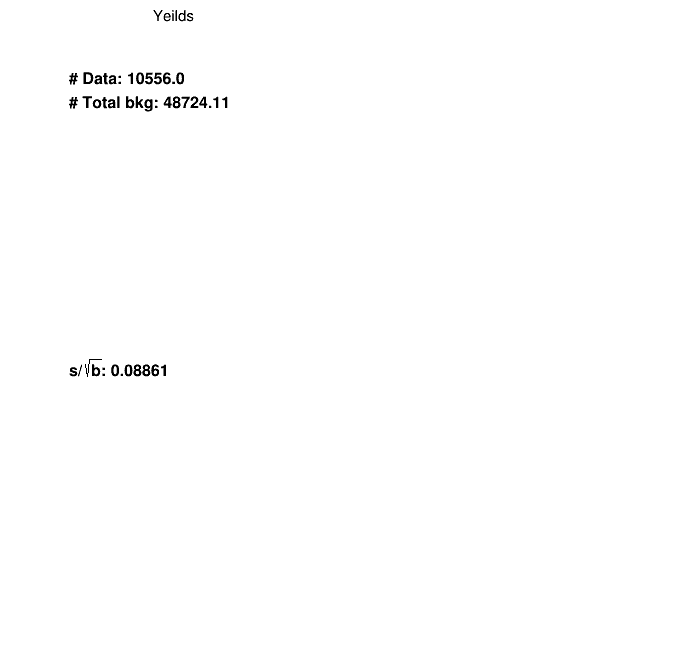

In [13]:
query_str = "mass_pre>100 and pt_lead_pre>80 and pt_trail_pre>40 and PuppiMET_pre>100"

if DRAW_SR:
    region = "SR"

    with Pool() as p:
        p.starmap(wrapper_mp, list_variables) 
#     wrapper_mp('mass_pre', [45, 100, 1000, 'M_{ll} [GeV]'])

    # for pie chart
    hist=HistStack(dic_df_raw, "pt_lead_pre", "weight", 31, 80,  660, "p_{T}(l_{lead}) [GeV]") 
    c1=hist.draw_hist("Zp-2500_CH-345", ERA, file_name=DATE+"/Presel/"+ERA+"/"+region+"/preselv1_"+query_str) 
    hist.get_yeilds()
    hist.draw_pie(file_name=DATE+"/Presel/"+ERA+"/"+region+"/pie_"+query_str)

In [31]:
# ###### wotop ######
# dic_variable={
#     "PuppiMET_pre": [14, 100, 660, "Puppi p_{T}^{miss} [GeV]"],    
#     "pt_lead_pre": [15, 80,  660, "p_{T}(l_{lead}) [GeV]"],
#     "pt_trail_pre": [15, 40, 520, "p_{T}(l_{trail}) [GeV]"], 
# }
# os.system("mkdir -p "+DATE+"/Presel/"+ERA+"/"+region+"/wotop")

# for variable, r in dic_variable.items():
#     if not "Puppi" in variable:
#         threshold = 0.3
#     else:
#         threshold = 0.5
#     hist=HistStack(dic_df_raw, variable, "weight", r[0], r[1], r[2], r[3])  
#     c1=hist.draw_hist("Zp-2500_CH-345", ERA, file_name=DATE+"/Presel/"+ERA+"/"+region+"/normblind_"+query_str, blind_from=threshold)        
#     hist=HistStack(dic_df_raw, variable, "weighthdampUp", r[0], r[1], r[2], r[3])  
#     c1=hist.draw_hist("Zp-2500_CH-345", ERA, file_name=DATE+"/Presel/"+ERA+"/"+region+"/normblind_hdampUp"+query_str, blind_from=threshold)
#     hist=HistStack(dic_df_raw, variable, "weighthdampDown", r[0], r[1], r[2], r[3])  
#     c1=hist.draw_hist("Zp-2500_CH-345", ERA, file_name=DATE+"/Presel/"+ERA+"/"+region+"/normblind_hdampDown"+query_str, blind_from=threshold)
#     hist=HistStack(dic_df_raw, variable, "weightPSUp", r[0], r[1], r[2], r[3])  
#     c1=hist.draw_hist("Zp-2500_CH-345", ERA, file_name=DATE+"/Presel/"+ERA+"/"+region+"/normblind_UEUp"+query_str, blind_from=threshold)
#     hist=HistStack(dic_df_raw, variable, "weightPSDown", r[0], r[1], r[2], r[3])  
#     c1=hist.draw_hist("Zp-2500_CH-345", ERA, file_name=DATE+"/Presel/"+ERA+"/"+region+"/normblind_UEDown"+query_str, blind_from=threshold)
#     hist=HistStack(dic_df_raw, variable, "wotop", r[0], r[1], r[2], r[3])  
#     c1=hist.draw_hist("Zp-2500_CH-345", ERA, file_name=DATE+"/Presel/"+ERA+"/"+region+"/wotop/norm_"+query_str, blind_from=threshold) 
# hist.get_yeilds()
# hist.draw_pie(file_name=DATE+"/Presel/"+ERA+"/"+region+"/wotop/pie_"+query_str)  

In [32]:
# ###### wobsf ######
# dic_variable={
#     "nbjetflav_pre": [10, 0, 10, "N bjetflav"],     
#     "pt_lead_pre": [15, 80,  660, "p_{T}(l_{lead}) [GeV]"],
# }
# os.system("mkdir -p "+DATE+"/Presel/"+ERA+"/"+region+"/wobsf")

# for variable, r in dic_variable.items():
#     if not "Puppi" in variable:
#         threshold = 0.3
#     else:
#         threshold = 0.5
#     hist=HistStack(dic_df_raw, variable, "weight", r[0], r[1], r[2], r[3])  
#     c1=hist.draw_hist("Zp-2500_CH-345", ERA, file_name=DATE+"/Presel/"+ERA+"/"+region+"/normblind_"+query_str, blind_from=threshold)        
#     hist=HistStack(dic_df_raw, variable, "wobsf", r[0], r[1], r[2], r[3])  
#     c1=hist.draw_hist("Zp-2500_CH-345", ERA, file_name=DATE+"/Presel/"+ERA+"/"+region+"/wobsf/norm_"+query_str, blind_from=threshold) 

Warning in <TCanvas::Constructor>: Deleting canvas with same name: c1
Info in <TCanvas::Print>: pdf file 20230622jer_18/Presel/ee18/SR/normblind_mass_pre>100 and pt_lead_pre>80 and pt_trail_pre>40 and PuppiMET_pre>100_nbjetflav_prebreakdown.pdf has been created
Info in <TCanvas::Print>: pdf file 20230622jer_18/Presel/ee18/SR/normblind_mass_pre>100 and pt_lead_pre>80 and pt_trail_pre>40 and PuppiMET_pre>100_nbjetflav_pre.pdf has been created
Warning in <TCanvas::Constructor>: Deleting canvas with same name: c1
Info in <TCanvas::Print>: pdf file 20230622jer_18/Presel/ee18/SR/wobsf/norm_mass_pre>100 and pt_lead_pre>80 and pt_trail_pre>40 and PuppiMET_pre>100_nbjetflav_prebreakdown.pdf has been created
Info in <TCanvas::Print>: pdf file 20230622jer_18/Presel/ee18/SR/wobsf/norm_mass_pre>100 and pt_lead_pre>80 and pt_trail_pre>40 and PuppiMET_pre>100_nbjetflav_pre.pdf has been created
Warning in <TCanvas::Constructor>: Deleting canvas with same name: c1
Info in <TCanvas::Print>: pdf file 202

# Signal Acc x Eff x presel

Warning in <TCanvas::Constructor>: Deleting canvas with same name: c1
Info in <TCanvas::Print>: pdf file 20230622jer_18/Presel/ee18/SR/sig_eff.pdf has been created


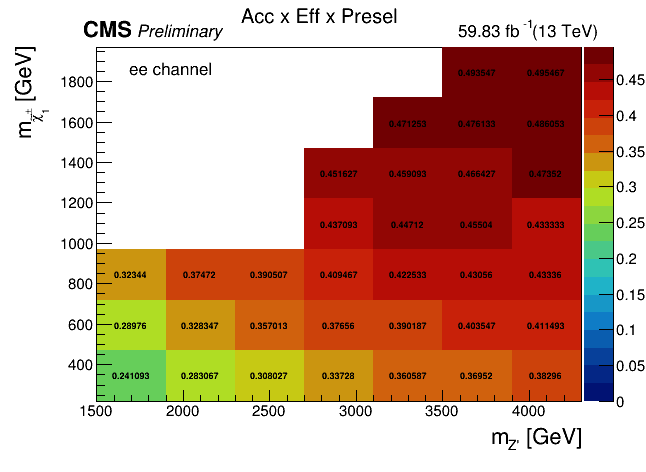

In [14]:
str_channel, str_lumi = HistStack.get_str_lumi_channel(ERA, ERA)

Zp_mass=[1700, 2100, 2500, 2900, 3300, 3700, 4100]
CH_mass=[345, 595, 845, 1095, 1345, 1595, 1845]
c1=rt.TCanvas("c1", "c1", 650, 500)
c1.SetLeftMargin(0.15)
c1.SetBottomMargin(0.15)
h2d1=rt.TH2D("h2d1", "", len(Zp_mass), Zp_mass[0]-200, Zp_mass[-1]+200, len(CH_mass), CH_mass[0]-125, CH_mass[-1]+125)
h2d1.SetTitle("Acc x Eff x Presel")

n_sig_in = 150000/4
if "em" in ERA:
    n_sig_in = 150000/2

for key in dic_df_raw:
    if not "Zp" in key:
        continue
    tmp=key.replace('_', '-')
    tmp=tmp.split('-')
    
    MZp=tmp[1]
    MCH=tmp[3]
    binx=Zp_mass.index(int(MZp))+1
    biny=CH_mass.index(int(MCH))+1
    h2d1.SetBinContent(binx, biny, dic_df_raw[key].shape[0]/(n_sig_in))
# # missing bin by hand
# h2d1.SetBinContent(5, 3, 40000/(n_sig_in)) #mumu: 23500, #ee: 20000
# h2d1.SetBinContent(3, 4, 40000/(n_sig_in)) #mumu: 23500, #ee: 20000

# set_palette("rainbow",255)
rt.gStyle.SetOptStat(0)
rt.gStyle.SetPalette(55)

h2d1.Draw("colz text")
h2d1.SetYTitle("m_{#tilde#chi_{1}^{#pm}} [GeV]")
h2d1.SetXTitle("m_{Z'} [GeV]")
h2d1.GetYaxis().SetTitleSize(0.05)
h2d1.GetXaxis().SetTitleSize(0.05)
latex=rt.TLatex()
latex.DrawLatexNDC( 0.2,0.84, "#scale[0.8]{#font[42]{"+str_channel+" channel}}")

latex1=rt.TLatex()
latex1.DrawLatexNDC(0.71, 0.92, "#font[42]{#scale[0.8]{"+str_lumi+" fb^{-1}(13 TeV)}}");
latex1.DrawLatexNDC(0.13, 0.92, "#font[62]{CMS}#font[42]{#it{#scale[0.8]{ Preliminary}}}");
 
c1.Draw()
c1.SaveAs(DATE+"/Presel/"+ERA+"/"+region+"/sig_eff.pdf")